# A principal component entropy metric for assessing global synchronicity in EEG signals

In [ ]:
# Main imports
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Matplot lib settings
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

## Principal component (PC) entropy

In [ ]:
def pc_entropy(x: np.ndarray):
    """ 
    Compute the PC-entropy for a matrix.  
    
    Args:
        x (np.ndarray): a matrix (..., N , M ) where N is the number of samples and M is the number of channels

    Return:
        The PC-entropy value. For matrices with more than two dimensions the PC-entropy will be iterated along the other dimensions.

    """
    channels_index = -1  
    samples_index = -2
    samples_n = x.shape[samples_index] # N
    channels_n = x.shape[channels_index] # M

    # computing covariance matrixes
    c = x - x.mean(axis=samples_index, keepdims=True)
    c_t = np.swapaxes(c, samples_index, channels_index)
    cov =  c_t @ c / (samples_n - 1)

    assert cov.shape[-2:] == (channels_n, channels_n)

    # compute the eigenvalues
    lam = np.linalg.eigvalsh(cov)
    lam = np.clip(lam, 0, None) # Clipping minimum value to avoid numerical errors

    # normalize the eigenvalues
    p = lam / lam.sum(axis=-1, keepdims=True)

    plogp = np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0.0)

    return  -plogp.sum(axis=-1) / np.log2(channels_n)

## Kuramoto model

In [ ]:
from scipy.integrate import solve_ivp
from joblib import Parallel, delayed
from typing import NamedTuple

# This is the ODE equation from the paper
def rhs(t, th, omega, G, K, M):
        # outer compute the matrix of differences
        coupling = (G * np.sin(-np.subtract.outer(th, th))).sum(axis=1)
        return omega + (K / M) * coupling

# this computes R
def order_parameter(th, axis=0):
    return np.abs(np.exp(1j * th).sum(axis=axis)) / th.shape[0]


class KuramotoResult(NamedTuple):
    order_parameter: float
    pc_entropy: float
    pc_entropy_denorm: float

def sample_from_kuramoto_model(
    coupling_constant: float, 
    number_of_oscillators: int, 
    fs: float, 
    number_of_samples: int, 
    transition_time: float =100, 
    seed=42
) -> np.ndarray:
    # setting random seed
    rng = np.random.default_rng(seed)

    # frequencies
    omegas = rng.normal(1, 0.25, number_of_oscillators) # rad/s
    # weights
    G = rng.normal(1, 0.25, (number_of_oscillators, number_of_oscillators))

    t_eval = transition_time + np.arange(number_of_samples) / fs
    th0 = rng.normal(0, np.pi/2, number_of_oscillators)
    sol = solve_ivp(rhs, (0, t_eval[-1]), th0, t_eval=t_eval,
                    args=(omegas, G, coupling_constant, number_of_oscillators), rtol=1e-6, atol=1e-8)
    assert sol.y.shape == (number_of_oscillators, number_of_samples) # the solution should be n_samples for M oscillators

    # raise an error if numerical integration fails
    if not sol.success:
        raise RuntimeError(sol.message)

    return sol.y

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

fs = 10
N = 1024
M = 5
transition_time = 100

def f(k):
    return sample_from_kuramoto_model(
        number_of_oscillators=M,
        coupling_constant=k,
        fs=fs,
        number_of_samples=N,
        transition_time=transition_time
    )

t = np.arange(0, N) / fs + transition_time
k_count = 100
ks = np.linspace(0, 1, k_count)

thetas = []

for k in ks:
    thetas.append(f(k))


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
lines = [ax.plot([], [], lw=1.5)[0] for _ in range(M)]
title = ax.set_title("")

ax.set_xlim(100, 120)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("Time (s)")

def update(frame):
    i, k = frame
    theta = thetas[i]
    for line, osc in zip(lines, np.sin(theta)):
        line.set_data(t, osc)
    title.set_text(f"K = {k:.2f}, R = {order_parameter(theta).mean():.2f}")
    return (*lines, title)


parameters = list(enumerate(ks))
anim = FuncAnimation(fig, update, frames=parameters, interval=100)
anim.save("kuramoto_model_animation.gif", writer=PillowWriter(fps=20))
plt.close(fig)

In [ ]:

def job(
    coupling_constant: float, 
    number_of_oscillators: int, 
    fs: float, 
    number_of_samples: int, 
    transition_time: float, 
    seed: int
) -> KuramotoResult:
    y = sample_from_kuramoto_model(
        coupling_constant=coupling_constant,
        number_of_oscillators=number_of_oscillators,
        fs=fs,
        number_of_samples=number_of_samples,
        transition_time=transition_time,
        seed=seed
    )

    pc_entropy_ = pc_entropy(np.sin(y.T))
    pc_entropy_denorm = pc_entropy_ * np.log2(number_of_oscillators)  
    # order parameter is computed along axis 0 which is the number of oscillators (as in the paper)
    # so we are left with an order parameter means along the oscillator for each sample.
    # To asses the sinchronicity of the system we compute the mean between them
    order_parameters = order_parameter(y, axis=0)

    return KuramotoResult(order_parameters.mean(), pc_entropy_, pc_entropy_denorm)

class KuramotoRunsResult(NamedTuple):
    coupling_constants: np.ndarray
    order_parameters: np.ndarray
    order_parameters_sem: np.ndarray
    pces: np.ndarray
    pces_sem: np.ndarray
    pces_denorm: np.ndarray
    pces_denorm_sem: np.ndarray

def kuramoto_runs(
        number_of_oscillators: int, 
        coupling_constant_max: float, 
        coupling_constant_count: int, 
        fs: float, 
        number_of_samples: int,
        transition_time=100, 
        number_of_runs=50,
        seed=42
    ) -> KuramotoRunsResult:
    """Run a specified number of runs of a Kuramoto experiment with different values of the coupling constants. Returns results for each value of the coupling constant averaged between the runs

    Args:
        number_of_oscillators (int): the number of oscillators.
        coupling_constant_max (float): the maximum value of the coupling constant for which Kuramoto is run.
        coupling_constant_count (int): the number of coupling constant. The resulting coupling constants will be the one in the range between 0 and the maximu value with step maximum divided by this parameter.
        fs (float): the sampling frequency used to sample from the Kuramoto model.
        number_of_samples (int): the number of samples to be taken.

    Keyword Args:
        transition_time (default=100): the instant of time from which the samples are taken
        number_of_runs (default=50): the number of runs.
        seed (default=42): the seed, used for reproducibility.
    """
    ks = np.linspace(0, coupling_constant_max, coupling_constant_count)

    out = Parallel(n_jobs=-1)(
        delayed(job)(K, number_of_oscillators, fs, number_of_samples, transition_time, [seed, i, r])
        for i, K in enumerate(ks) for r in range(number_of_runs)
    )

    out = np.array(out).reshape(coupling_constant_count, number_of_runs, 3)
    r, pce, pce_dn = out[..., 0], out[..., 1], out[..., 2]

    sem = lambda a: a.std(axis=1, ddof=1) / np.sqrt(number_of_runs)
    return KuramotoRunsResult(
        ks, 
        r.mean(axis=1), 
        sem(r), 
        pce.mean(axis=1), 
        sem(pce), 
        pce_dn.mean(axis=1), 
        sem(pce_dn)
    )

In [ ]:
# Fixed window length experiments
number_of_oscillators = 30
coupling_constant_max = 0.8
coupling_constant_step = 20
window_length = 819.2

fss = [0.625, 1.25, 2.5]

kuramotos_fixed_window_length = {fs : kuramoto_runs(
    number_of_oscillators=number_of_oscillators,
    coupling_constant_max=coupling_constant_max,
    coupling_constant_count= coupling_constant_step,
    fs=fs,
    number_of_samples=int(window_length*fs)
) for fs in fss}

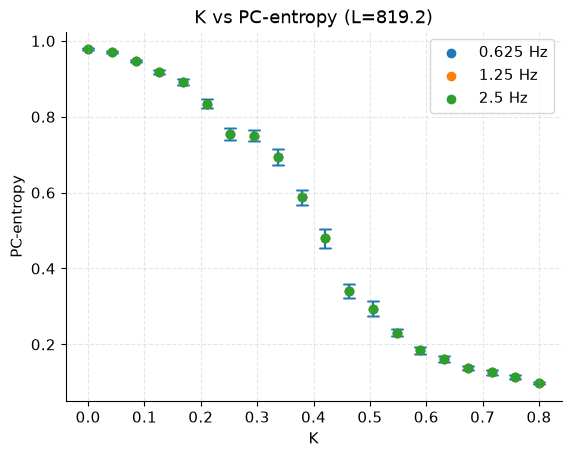

In [ ]:
for fs, kuramoto in kuramotos_fixed_window_length.items():
    ks, rs, _ , pces, errs, _, _ = kuramoto
    plt.errorbar(ks, pces, yerr=errs, fmt='none', capsize=4, zorder=1)
    plt.scatter(ks, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('K vs PC-entropy (L=819.2)')
plt.xlabel('K')
plt.ylabel('PC-entropy')
plt.show()

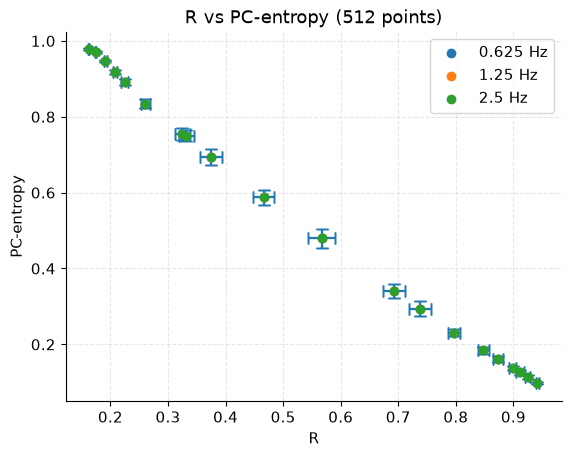

In [ ]:
for fs, kuramoto in kuramotos_fixed_window_length.items():
    k_, rs, rs_sem, pces, pces_sem, _, _ = kuramoto
    plt.errorbar(rs, pces, xerr=rs_sem, yerr=pces_sem, fmt='none', capsize=4, zorder=1)
    plt.scatter(rs, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('R vs PC-entropy (512 points)')
plt.xlabel('R')
plt.ylabel('PC-entropy')
plt.show()

In [ ]:
# Fixed samples experiments
number_of_oscillators = 30
coupling_constant_max = 0.8
coupling_constant_step = 20
number_of_samples = 512

fss = [0.625, 1.25, 2.5]

kuramotos_fixed_sampling_n = {fs : kuramoto_runs(
    number_of_oscillators=number_of_oscillators,
    coupling_constant_max=coupling_constant_max,
    coupling_constant_count=coupling_constant_step,
    fs=fs,
    number_of_samples=number_of_samples
) for fs in fss}

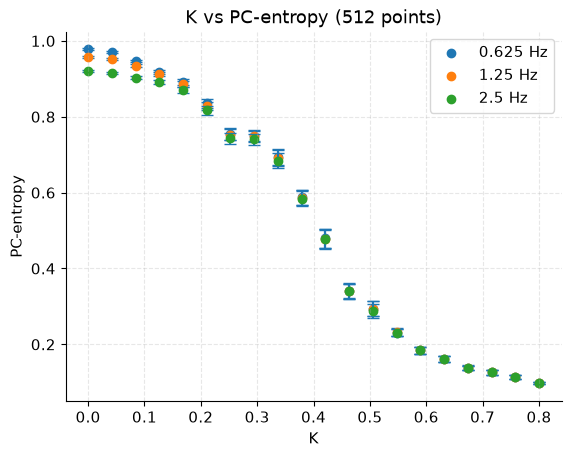

In [ ]:
for fs, kuramoto in kuramotos_fixed_sampling_n.items():
    ks, rs, order_apr, pces, errs, _, _ = kuramoto
    plt.errorbar(ks, pces, yerr=errs, fmt='none', capsize=4, zorder=1)
    plt.scatter(ks, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('K vs PC-entropy (512 points)')
plt.xlabel('K')
plt.ylabel('PC-entropy')
plt.show()

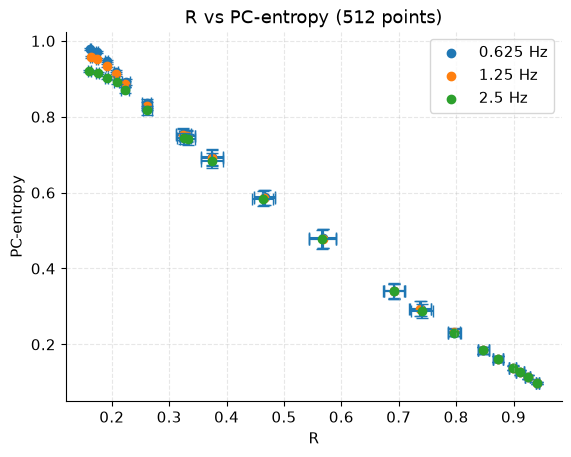

In [ ]:
for fs, kuramoto in kuramotos_fixed_sampling_n.items():
    k_, rs, rs_sem, pces, pces_sem, _, _ = kuramoto
    plt.errorbar(rs, pces, xerr=rs_sem, yerr=pces_sem, fmt='none', capsize=4, zorder=1)
    plt.scatter(rs, pces, label=f'{fs:.4g} Hz')

plt.legend()
plt.title('R vs PC-entropy (512 points)')
plt.xlabel('R')
plt.ylabel('PC-entropy')
plt.show()

In [ ]:
fs = 0.625
kuramoto30 = kuramotos_fixed_sampling_n[fs]

kuramoto20 = kuramoto_runs(
    number_of_oscillators=20,
    coupling_constant_max=0.8,
    coupling_constant_count=20,
    fs=fs,
    number_of_samples=512,
)

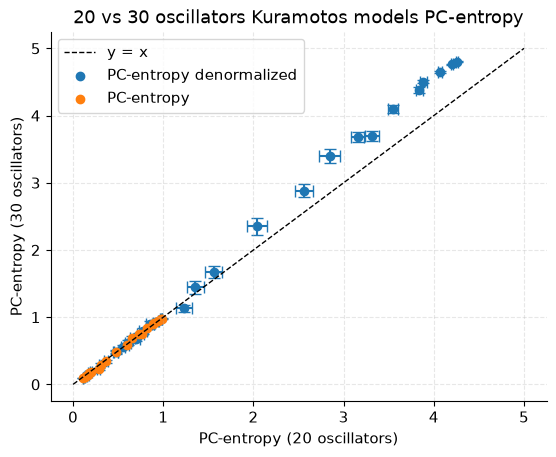

In [ ]:
lim = [0, 5]
plt.plot(lim, lim, "k--", lw=1, label="y = x")

plt.scatter(x=kuramoto20.pces_denorm, y=kuramoto30.pces_denorm, label='PC-entropy denormalized')
plt.errorbar(
    x=kuramoto20.pces_denorm, 
    y=kuramoto30.pces_denorm, 
    xerr=kuramoto20.pces_denorm_sem, 
    yerr=kuramoto30.pces_denorm_sem, 
    fmt='none', 
    capsize=4, 
    zorder=1
)

plt.scatter(x=kuramoto20.pces, y=kuramoto30.pces, label='PC-entropy')
plt.errorbar(
    x=kuramoto20.pces, 
    y=kuramoto30.pces, 
    xerr=kuramoto20.pces_sem, 
    yerr=kuramoto30.pces_sem, 
    fmt='none', 
    capsize=4, 
    zorder=0
)

plt.title('20 vs 30 oscillators Kuramotos models PC-entropy')
plt.ylabel('PC-entropy (30 oscillators)')
plt.xlabel('PC-entropy (20 oscillators)')
plt.legend()
plt.show()

## Analysis on the arithmetic task dataset

In [ ]:
import physionet
from pathlib import Path

DATA_DIR = Path("eegmat-1.0.0")

# Download the database if not already present
if not DATA_DIR.exists():
    physionet.download("eegmat", version="1.0.0", output_dir=str(DATA_DIR))

In [ ]:
info = physionet.load("eegmat", table="subject-info", version="1.0.0")
info

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0
5,Subject05,16,F,2010,20.71,1
6,Subject06,18,M,2011,4.35,0
7,Subject07,18,F,2012,13.38,1
8,Subject08,26,M,2011,18.24,1
9,Subject09,16,F,2010,7.00,0
